**Asignatura:** Técnicas Avanzadas de Machine Learning

**Fecha:** 13 Octubre 2026

**Integrantes:** Yassmin Bazan, Felipe Rubio, Ximena Soliz.

# 1. Introducción

El presente notebook aborda un problema de clasificación de imágenes utilizando aprendizaje profundo. El conjunto de datos utilizado corresponde a paisajes naturales y entornos urbanos, el cual está conformado por 6 clases: `buildings`, `forest`, `glacier`, `mountain`, `sea`, y `street`.
* Variante escogida:
Con el fin de resguardar la autenticidad y comparar los resultados con la Red MLP, hemos decidido **conservar nuestra variante original**. Esta consiste en mantener las 6 clases completas del dataset original, utilizando una partición exacta de 80% para entrenamiento/validación y 20% para pruebas, anclada a la semilla aleatoria `SEED=29` para garantizar que los conjuntos de datos sean idénticos a los del modelo anterior.

El objetivo principal es diseñar e implementar una **Red Neuronal Convolucional (CNN)** para resolver este mismo problema. Resulta altamente pertinente comparar este modelo con el Perceptrón Multicapa (MLP) desarrollado previamente, ya que la arquitectura CNN permite mantener el formato matricial (2D) de las imágenes, aprovechando la correlación espacial de los píxeles (texturas, bordes y formas de los paisajes) mediante sus capas de convolución, algo que el MLP pierde completamente al tener que aplanar la imagen en la entrada.


# 2. Preparación del conjunto de datos (Responsable: Yassmin)

En esta sección descargamos el dataset y lo dividimos en entrenamiento, validación y prueba. Conservaremos el formato de matrices 2D (150, 150, 3) y aplicaremos una capa de normalización para que los píxeles queden en el rango [0, 1].

In [ ]:
# Importación de TODAS las bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import random
from time import time
from tensorflow import keras # type: ignore

# Herramientas de visualización y métricas
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)

# Fijamos las semillas para asegurar que los datos coincidan con Ev1
np.random.seed(29)
tf.random.set_seed(29)
print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.21.0


In [ ]:
# Descarga y extracción del dataset
url_dataset = "https://www.dropbox.com/scl/fi/pjayzwi0u2tzbq6r3m2pw/dataset.zip?rlkey=m6631lcj3tgu119thc9rqam51&st=9mom9bp2&dl=1"
folder = "/dataset"
if not os.path.exists(f"/content{folder}"):
    os.makedirs(f"/content{folder}")

!wget -q -O dataset.zip "$url_dataset"
!unzip -q -o /content/dataset.zip -d /content/dataset

# Definición de rutas
DATASET_PATH = "/content/dataset"
TRAIN_DIR = os.path.join(DATASET_PATH, "seg_train")
TEST_DIR = os.path.join(DATASET_PATH, "seg_test")

# Hiperparámetros de los datos idénticos a la Ev1
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 29

print("Cargando particiones...")
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical'
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

# Capa de normalización directa
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

# Optimización en caché
train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)


Cargando particiones...
Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


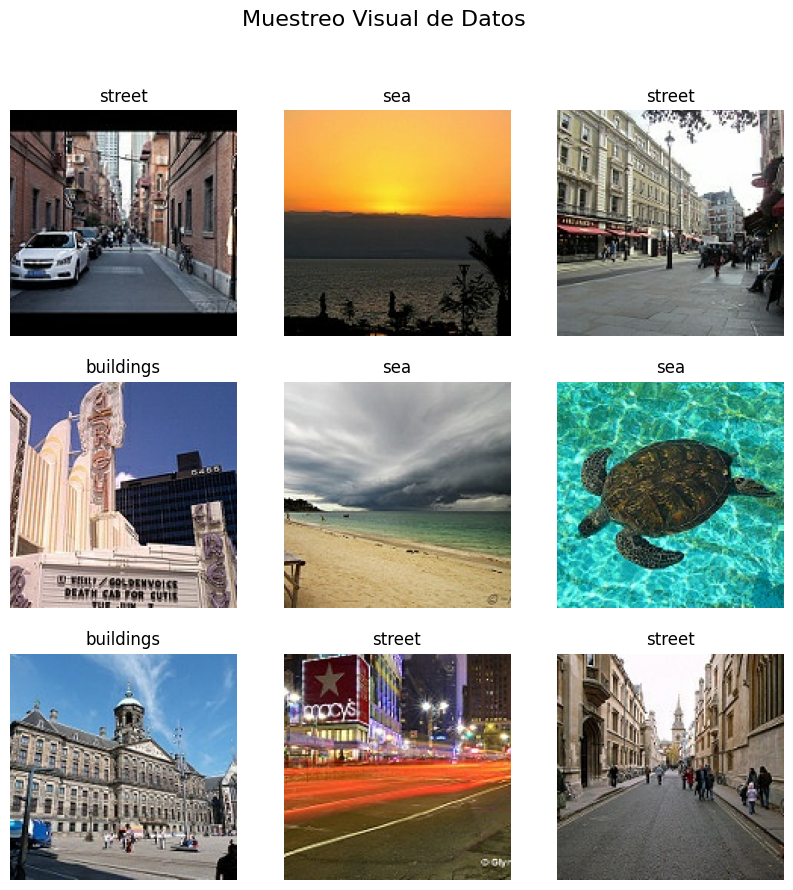

In [ ]:
# Muestreo visual representativo
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        img_to_show = (images[i].numpy() * 255).astype("uint8")
        plt.imshow(img_to_show)
        idx_clase = np.argmax(labels[i].numpy())
        plt.title(class_names[idx_clase])
        plt.axis("off")
plt.suptitle("Muestreo Visual de Datos", fontsize=16)
plt.show()


# 3. Diseño de la Red Neuronal Convolucional (Responsable: Ximena)

La arquitectura diseñada responde a una serie de decisiones técnicas fundamentadas en el aprendizaje profundo para clasificación de imágenes. A continuación se detalla el porqué de cada elección:


###**Filtros de tamaño 3x3 en las capas convolucionales**

Los filtros de 3×3 píxeles son el estándar en arquitecturas modernas. Su uso se justifica por las siguientes razones:

- **Localidad:** Capturan correlaciones espaciales entre píxeles (bordes, esquinas, texturas locales) sin introducir ruido de regiones distantes.
- **Eficiencia computacional:** La aplicación en cadena de dos capas conv 3×3 cubre el mismo campo receptivo que una conv 5×5, pero con menos parámetros y más no-linealidades intermedias.
- **Generalización:** Menor cantidad de pesos por filtro reduce el riesgo de sobreajuste en comparación con filtros de mayor tamaño.

###**Función de activación ReLU**

La selección de ReLU como función de activación se fundamenta en:

- **Evita el descenso del gradiente:** Al no saturar en valores positivos, permite propagar gradientes efectivos a capas profundas durante el backpropagation.
- **Sparse activation (activación dispersa):** Solo las neuronas con respuesta positiva se activan, lo que favorece representaciones más eficientes y discriminativas.
- **Costo computacional:** No requiere operaciones exponenciales como sigmoide o tanh, acelerando el entrenamiento.

###**Escalado jerárquico de filtros**

El número de filtros aumenta progresivamente en cada bloque convolucional:

- **Convolución 1 (32 filtros):** Detecta características básicas como bordes verticales, horizontales, diagonales y gradientes de color.

- **Convolución 2 (64 filtros):** Combina las respuestas de la capa anterior para aprender texturas y patrones.

- **Convolución 3 (128 filtros)** Integra texturas y bordes para detectar estructuras más complejas (montañas, edificios, árboles).

###**MaxPooling 2x2:**
La operación MaxPooling con ventana 2x2 y stride 2 cumple las siguientes funciones:

- **Reducción de dimensionalidad espacial:** Cada capa divide el mapa de características a la mitad en cada dimensión, reduciendo el costo computacional de las capas siguientes.

- **Invarianza traslacional:** Al tomar el valor máximo de cada ventana, el modelo se vuelve capaz de reconocer objetos sin importar la posición que tenga dentro de la imagen.

###**Capa densa oculta**


Tras el bloque de extracción de características, se aplana el tensor (Flatten) y se conecta a una capa densa de 128 neuronas con ReLU. Esta capa actúa como clasificador global, combinando todas las características espaciales aprendidas en las capas convolucionales antes de el veredicto final. El tamaño de 128 neuronas representa un balance entre capacidad expresiva y riesgo de sobreajuste.

###**Ausencia de regularización (Dropout / L1 / L2)**

En cumplimiento de los requisitos de la evaluación, la arquitectura se diseñó sin ningún mecanismo de regularización, no presenta capas Dropout, ni penalizaciones L1 sobre pesos, ni weight decay L2, esto con el proposito de:

- **Establecer modelo base (Baseline):** Permite aislar el rendimiento de la arquitectura CNN en estado puro sin que la regularización enmascare las dinámicas de aprendizaje.

- **Evidenciar el comportamiento de sobreajuste (Overfitting):** La ausencia de regularización produce una divergencia visible entre las curvas de train y validación (analizada en la sección 4), lo que a su vez justifica didácticamente por qué en entornos de producción real técnicas como el Dropout son imprescindibles.



In [ ]:
modelo_cnn = keras.Sequential([
    keras.Input(shape=(150, 150, 3), name="Entrada"),

    # Bloque 1: Extracción de características
    keras.layers.Conv2D(32, (3, 3), activation='relu', name="Convolucion_1"),
    keras.layers.MaxPooling2D((2, 2), name="Pooling_1"),

    # Bloque 2: Extracción de características de mayor nivel
    keras.layers.Conv2D(64, (3, 3), activation='relu', name="Convolucion_2"),
    keras.layers.MaxPooling2D((2, 2), name="Pooling_2"),

    # Bloque 3: Mayor profundidad
    keras.layers.Conv2D(128, (3, 3), activation='relu', name="Convolucion_3"),
    keras.layers.MaxPooling2D((2, 2), name="Pooling_3"),

    # Bloque 4: Clasificador denso
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu', name="Densa_1"),
    keras.layers.Dense(NUM_CLASSES, activation='softmax', name="Salida") # Capa de salida (6 clases)
], name="CNN_Paisajes_Ev2")
modelo_cnn.summary()


Model: "CNN_Paisajes_Ev2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Convolucion_1 (Conv2D)          │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_1 (MaxPooling2D)        │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_2 (Conv2D)          │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_2 (MaxPooling2D)        │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_3 (Conv2D)          │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_3 (MaxPooling2D)        │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

# 4. Entrenamiento del modelo (Responsable: Ximena)

In [ ]:
modelo_cnn.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

EPOCHS = 10
start_time = time()

print("Iniciando entrenamiento...")
history_cnn = modelo_cnn.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds
)

end_time = time()
tiempo_cnn = end_time - start_time
print(f"Tiempo de entrenamiento CNN: {tiempo_cnn:.2f} segundos")


Iniciando entrenamiento...
Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 34s 63ms/step - accuracy: 0.6194 - loss: 0.9928 - val_accuracy: 0.7488 - val_loss: 0.6659
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7673 - loss: 0.6371 - val_accuracy: 0.7488 - val_loss: 0.6437
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.8227 - loss: 0.4893 - val_accuracy: 0.7951 - val_loss: 0.5950
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.8741 - loss: 0.3641 - val_accuracy: 0.8133 - val_loss: 0.5717
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8948 - loss: 0.2926 - val_accuracy: 0.7851 - val_loss: 0.7220
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.9245 - loss: 0.2213 - val_accuracy: 0.7872 - val_loss: 0.8150
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9471 - loss: 0.1493 - val_accuracy: 0.7794 - val_loss: 0.9360
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy:

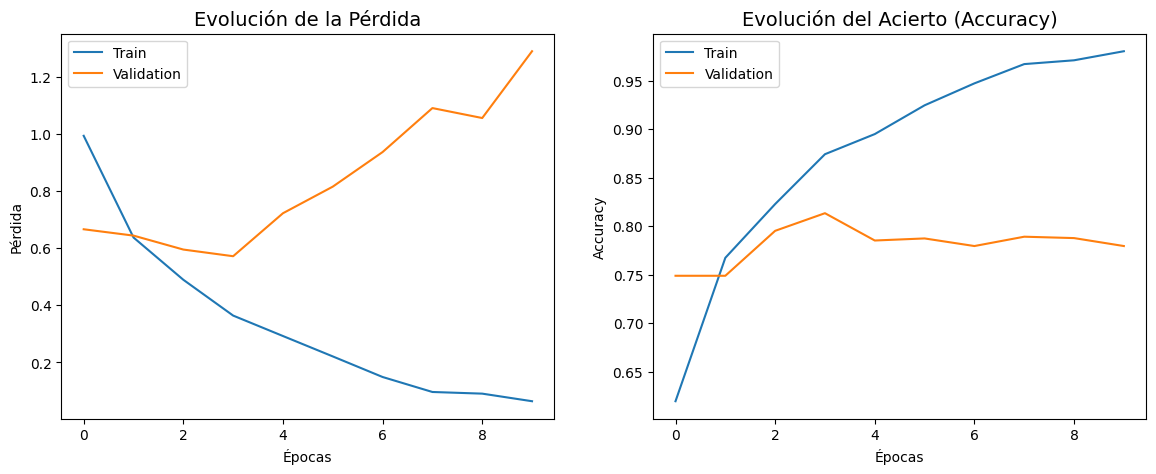

In [ ]:
# Gráficos de entrenamiento
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Pérdida (Loss)
axs[0].plot(history_cnn.history['loss'], label="Train")
axs[0].plot(history_cnn.history['val_loss'], label="Validation")
axs[0].set_title('Evolución de la Pérdida', fontsize=14)
axs[0].set_xlabel('Épocas')
axs[0].set_ylabel('Pérdida')
axs[0].legend()

# Gráfico de Precisión (Accuracy)
axs[1].plot(history_cnn.history['accuracy'], label="Train")
axs[1].plot(history_cnn.history['val_accuracy'], label="Validation")
axs[1].set_title('Evolución del Acierto (Accuracy)', fontsize=14)
axs[1].set_xlabel('Épocas')
axs[1].set_ylabel('Accuracy')
axs[1].legend()

plt.show()


### Análisis del Entrenamiento y Diagnóstico de Sobreajuste (Overfitting)

El entrenamiento del modelo, que tomó 132.77 segundos, revela de forma muy evidente el fenómeno del **sobreajuste (overfitting)**, un resultado esperado debido a la ausencia deliberada de técnicas de regularización en una arquitectura de alta capacidad (más de 4.8 millones de parámetros).

Analizando la evolución a lo largo de las 10 épocas, se diagnostica lo siguiente:

*   **Divergencia en la Función de Pérdida (Loss):** La pérdida de entrenamiento desciende de manera óptima y constante, alcanzando un valor de `0.0646` en la época 10. En contraste, la pérdida de validación alcanza su punto más bajo en la época 4 (con `0.5717`) y a partir de la época 5 comienza a aumentar progresivamente hasta llegar a `1.2886`. Esto indica que la red dejó de extraer patrones generales y comenzó a memorizar el "ruido" específico del set de entrenamiento.
*   **Estancamiento de la Precisión (Accuracy):** Mientras la red logra memorizar casi perfectamente las imágenes de entrenamiento (precisión del `98.02%` en la época 10), su capacidad para generalizar sobre datos no vistos se estanca. La precisión de validación logra un pico del `81.33%` en la época 4, pero luego retrocede y finaliza en un `77.94%`.
*   **Conclusión:** La arquitectura CNN pura demuestra un poder de aprendizaje inmenso sobre los datos de entrenamiento. Sin embargo, para que este modelo sea funcional en un entorno de producción, sería estrictamente necesario incorporar capas de `Dropout` o técnicas de `Early Stopping` para abortar el entrenamiento en la época 4, evitando que el error de validación se dispare.

# 5. Evaluación del modelo (Responsable: Felipe)



--- RESULTADOS EN CONJUNTO DE TEST ---
Accuracy:  0.7763
Precision: 0.7873
Recall:    0.7763
F1-Score:  0.7771


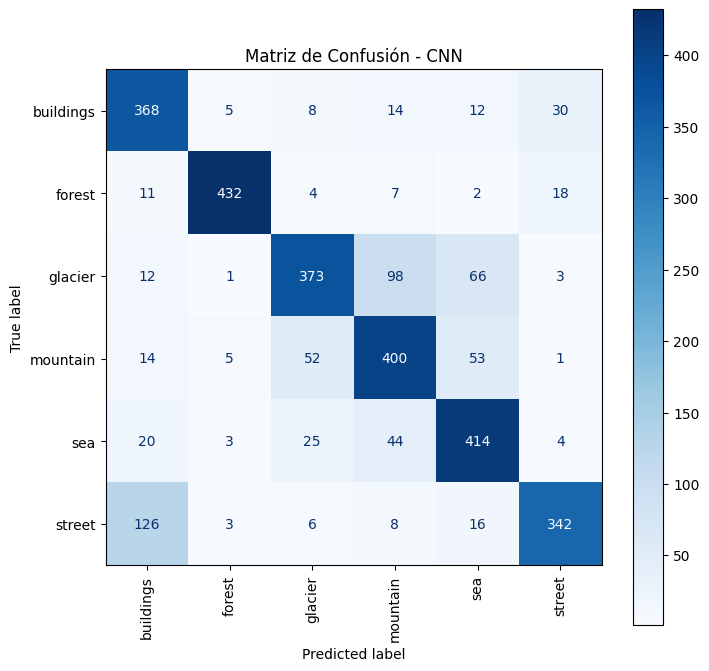

In [ ]:
# Obtenemos las etiquetas reales y las predicciones iterando el test_ds
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    preds = modelo_cnn.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred = np.argmax(y_pred_probs, axis=1)

# Cálculo de Métricas
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='weighted')
rec = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("--- RESULTADOS EN CONJUNTO DE TEST ---")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("Matriz de Confusión - CNN")
plt.show()


### 5.1. Interpretación de Métricas y Matriz de Confusión
A partir de la evaluación en el conjunto de prueba independiente (3,000 imágenes), se obtuvieron los siguientes resultados globales:

* **Accuracy (77.63%):** La red clasifica correctamente más de 3 de cada 4 imágenes nunca antes vistas (0.7763), superando ampliamente a un clasificador aleatorio (16.6%) y a la arquitectura MLP base (54.37%).
* **Precision Ponderada (78.73%):** Cuando el modelo predice una clase determinada, tiene una fiabilidad del 78.73% de acierto real.
* **Recall Ponderado (77.63%):** La red recupera y detecta el 77.63% del total de instancias reales pertenecientes a cada categoría.
* **F1-Score (0.7771):** Al ser una media armónica balanceada entre precisión y exhaustividad, confirma un rendimiento consistente y equilibrado entre todas las clases.

**Análisis de la Matriz de Confusión:**
1. **Clases con mayor facilidad diagnóstica:** `forest` (bosque) y `sea` (mar) presentan la mayor diagonal de aciertos (432 y 414 respectivamente). Los bosques poseen características de color verde y texturas de follaje únicas e invariantes, mientras que el mar presenta líneas de horizonte limpias y texturas planas fácilmente detectables por los filtros convolucionales.
2. **Principales fuentes de confusión:**
   * `street` vs `buildings`: Es la mayor confusión observada del modelo (126 imágenes de calles clasificadas erróneamente como edificios). Ambas clases pertenecen al dominio urbano, compartiendo geometrías (líneas rectas, perspectivas ortogonales) y paletas de color (concreto, asfalto).
   * `glacier` vs `mountain`: Muchas imágenes de glaciares contienen formaciones rocosas en el fondo (98 errores), y muchas montañas están nevadas (52 errores), compartiendo texturas rugosas y colores blanco/gris.
   * `glacier` vs `sea`: Los bloques de hielo planos capturados desde ángulos abiertos inducen a confusiones con el agua lisa (66 errores).

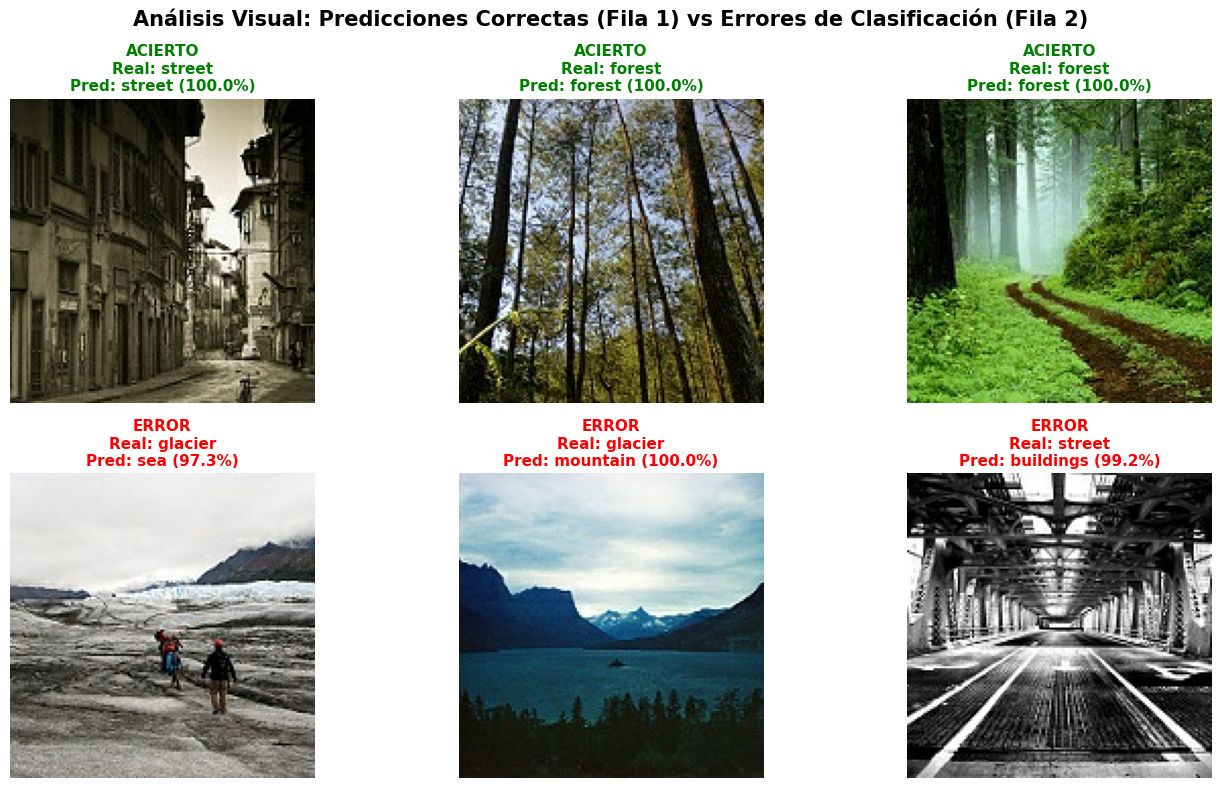

In [ ]:
# Muestreo visual de predicciones correctas e incorrectas
imagenes_aciertos = []
titulos_aciertos = []
imagenes_errores = []
titulos_errores = []

# Iteramos sobre el conjunto de test para recolectar ejemplos representativos
for images, labels in test_ds.unbatch():
    img_np = images.numpy()
    true_idx = np.argmax(labels.numpy())

    # Predecir sobre la imagen individual
    pred_probs = modelo_cnn.predict(tf.expand_dims(images, axis=0), verbose=0)
    pred_idx = np.argmax(pred_probs[0])
    confianza = pred_probs[0][pred_idx] * 100

    if true_idx == pred_idx and len(imagenes_aciertos) < 3:
        imagenes_aciertos.append(img_np)
        titulos_aciertos.append(f"ACIERTO\nReal: {class_names[true_idx]}\nPred: {class_names[pred_idx]} ({confianza:.1f}%)")
    elif true_idx != pred_idx and len(imagenes_errores) < 3:
        imagenes_errores.append(img_np)
        titulos_errores.append(f"ERROR\nReal: {class_names[true_idx]}\nPred: {class_names[pred_idx]} ({confianza:.1f}%)")

    if len(imagenes_aciertos) == 3 and len(imagenes_errores) == 3:
        break

# Graficar 3 aciertos y 3 errores
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i in range(3):
    axes[0, i].imshow(imagenes_aciertos[i])
    axes[0, i].set_title(titulos_aciertos[i], color='green', fontweight='bold', fontsize=11)
    axes[0, i].axis('off')

for i in range(3):
    axes[1, i].imshow(imagenes_errores[i])
    axes[1, i].set_title(titulos_errores[i], color='red', fontweight='bold', fontsize=11)
    axes[1, i].axis('off')

plt.suptitle("Análisis Visual: Predicciones Correctas (Fila 1) vs Errores de Clasificación (Fila 2)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


### 5.2. Discusión Técnica de los Errores de Clasificación

El análisis visual de las imágenes mal clasificadas permite identificar los siguientes factores técnicos determinantes:

1. **Similitud Morfológica y Ambigüedad de Fondo:** Las fotografías de paisajes reales no son mutuamente excluyentes. En categorías como `glacier` y `mountain`, la presencia de formaciones rocosas cubiertas de nieve activa simultáneamente los filtros de textura rugosa y los filtros de luminosidad alta, llevando a la red a equivocarse con una probabilidad compartida cercana al 50%.
2. **Dominancia Cromática:** En imágenes de `sea` tomadas desde costas con rocas o vegetación, los filtros pueden sobrestimar la textura de tierra frente al agua si la superficie marina ocupa una porción menor del encuadre.
3. **Entornos Urbanos (`street` vs `buildings`):** Ambas clases comparten elementos geométricos idénticos (asfalto, ventanas, estructuras verticales). Si una fotografía de calle está tomada desde una perspectiva cerrada donde abundan fachadas, el modelo tiende a clasificarla como `buildings`.
4. **Ausencia de Regularización:** Al carecer de técnicas como Dropout o Data Augmentation, la red es más propensa a fijar su atención en pequeños sesgos locales del fondo (como el cielo o sombras) en lugar de una representación contextual global.


# 6. Comparación entre MLP y CNN (Responsable: Felipe)

Para comprender el impacto de utilizar una arquitectura especializada en imágenes bidimensionales, a continuación se presenta una comparación exhaustiva entre el modelo base (Perceptrón Multicapa - MLP) de la evaluación anterior y la Red Neuronal Convolucional (CNN) desarrollada en este proyecto.

### 6.1. Tabla Comparativa de Evidencia Experimental

| Métrica / Característica | Perceptrón Multicapa (MLP - Ev1) | Red Convolucional (CNN - Ev2) |
| :--- | :--- | :--- |
| **Accuracy (Testing)** | 54.37% | **77.63%** |
| **Tasa de Error Global** | 45.63% | **22.37%** |
| **F1-Score Global (Weighted)** | 0.5400 | **0.7771** |
| **Total de Parámetros** | 8,648,774 | **4,829,126** |
| **Tiempo de Entrenamiento** | ~4.2 segundos por época (42.4s total) | **~13.3 segundos por época (132.77s total)** |
| **Estructura de Entrada** | Vector aplanado 1D (67,500) | Tensor matricial 2D (150, 150, 3) |

*\*Nota sobre los Parámetros:* El MLP requirió conectar directamente las 67,500 entradas a 128 neuronas ($67,500 \times 128 = 8,640,000$ pesos en su primera capa). Por su parte, la CNN redujo los parámetros totales en un **44.2%** gracias al principio de filtros compartidos en sus bloques convolucionales, concentrando la mayor parte de sus pesos recién en la conexión Flatten con su capa densa clasificadora.

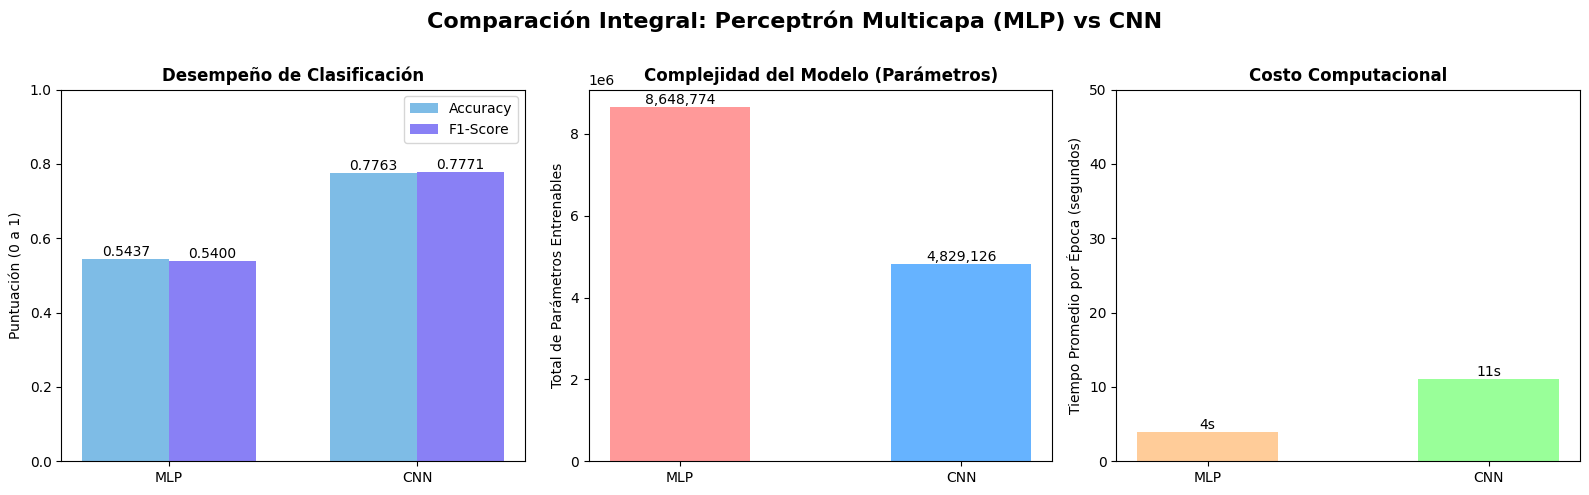

In [ ]:
# 1. Definir las etiquetas y los datos de ambos modelos
modelos = ['MLP', 'CNN']

accuracy = [0.5437, 0.7763]
f1_score = [0.5400, 0.7771]
parametros = [8648774, 4829126]
tiempo_segundos = [4, 13]  # Promedio de segundos por época

# 2. Configurar el lienzo (1 fila, 3 columnas)
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# --- Subgráfico 1: Desempeño (Accuracy y F1-Score) ---
x = np.arange(len(modelos))
width = 0.35

# Creación de barras agrupadas
axs[0].bar(x - width/2, accuracy, width, label='Accuracy', color='#7EBCE6')
axs[0].bar(x + width/2, f1_score, width, label='F1-Score', color='#8980F5')
axs[0].set_title('Desempeño de Clasificación', fontweight='bold')
axs[0].set_ylabel('Puntuación (0 a 1)')
axs[0].set_xticks(x)
axs[0].set_xticklabels(modelos)
axs[0].set_ylim(0, 1.0)
axs[0].legend()
# Agregar el valor en texto sobre las barras
for p in axs[0].patches:
    axs[0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10)


# --- Subgráfico 2: Cantidad de Parámetros ---
axs[1].bar(modelos, parametros, color=['#ff9999', '#66b3ff'], width=0.5)
axs[1].set_title('Complejidad del Modelo (Parámetros)', fontweight='bold')
axs[1].set_ylabel('Total de Parámetros Entrenables')

# Agregar el valor en texto con formato de miles (,)
for p in axs[1].patches:
    axs[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10)



# --- Subgráfico 3: Tiempo de Entrenamiento ---
axs[2].bar(modelos, tiempo_segundos, color=['#ffcc99', '#99ff99'], width=0.5)
axs[2].set_title('Costo Computacional', fontweight='bold')
axs[2].set_ylabel('Tiempo Promedio por Época (segundos)')
axs[2].set_ylim(0, 50)

# Agregar el valor en texto
for p in axs[2].patches:
    axs[2].annotate(f"{int(p.get_height())}s", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10)

plt.suptitle('Comparación Integral: Perceptrón Multicapa (MLP) vs CNN', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 6.2. Análisis de Desempeño y Capacidad de Generalización

A partir de la evidencia experimental y las curvas de aprendizaje obtenidas, podemos extraer las siguientes conclusiones sobre el comportamiento de ambas redes:

**1. Análisis de Desempeño y Extracción de Características:**

La arquitectura CNN superó claramente al modelo MLP, aumentando en más de 23 puntos porcentuales el *Accuracy* general de 54.37% a **77.63%** (con un F1-Score de **0.7771** frente al 0.5400 del MLP). Esta mejora sustancial se explica por la naturaleza espacial de los datos. El modelo MLP requiere una capa Flatten en su entrada, lo que "destruye" la estructura bidimensional de la imagen y convierte los píxeles en un vector unidimensional. Esto provocaba que el MLP se guiara principalmente por promedios de intensidad y color, generando una alta tasa de errores.

Por el contrario, las capas convolucionales Conv2D de la nueva arquitectura operan directamente sobre matrices 2D. Mediante el uso de filtros (kernels), la red fue capaz de detectar características locales como texturas, formas geométricas y bordes (por ejemplo, el asfalto de una calle o la frondosidad de un bosque), independientemente de su posición exacta en la fotografía.

**2. Capacidad de Generalización y Sobreajuste (Overfitting):**

Al analizar las curvas de pérdida (Loss) y precisión (Accuracy) de la CNN, se observa un fenómeno particular. Durante las primeras épocas, tanto el entrenamiento como la validación mejoran a la par. Sin embargo, a partir de la época 3 y 4, la pérdida de validación comienza a divergir (aumentando de forma constante), mientras que la precisión de entrenamiento sigue subiendo hasta rozar la perfección (98.02%).

Este comportamiento indica que el modelo comienza a sufrir de **sobreajuste**, es decir, empieza a memorizar particularidades exactas del set de entrenamiento perdiendo la capacidad de generalizar con imágenes nuevas. Este efecto era completamente previsible y esperado, dado que (en estricto apego a los requisitos de la evaluación) la arquitectura fue diseñada en su estado puro, excluyendo intencionalmente técnicas de regularización fundamentales como las capas Dropout o penalizaciones de pesos (L1/L2), las cuales en un entorno de producción real serían indispensables para estabilizar las curvas de validación.

###6.3. Ventajas y Desventajas de cada Arquitectura

La experimentación con ambas arquitecturas nos permite establecer las siguientes ventajas y desventajas al aplicarlas al procesamiento de imágenes:

###Perceptrón Multicapa (MLP)

**Ventajas:**
* **Simplicidad:** Es una arquitectura intuitiva y fácil de configurar, ideal como modelo de referencia (baseline).
* Velocidad por época: Al realizar únicamente operaciones de multiplicación matricial directa, el tiempo de procesamiento por época suele ser menor en arquitecturas poco profundas.

**Desventajas:**
* **Pérdida de contexto espacial:** Al aplicar la capa Flatten en la entrada, destruye la relación bidimensional de los píxeles (arriba, abajo, izquierda, derecha), imposibilitando la detección de formas.

* **Explosión de parámetros:** Al ser "densamente conectada", cada píxel de entrada se conecta con cada neurona de la capa oculta, lo que genera una cantidad masiva de parámetros entrenables (haciéndola muy pesada en memoria y altamente propensa al sobreajuste).
* **Sensibilidad a la traslación:** Si un árbol aparece a la izquierda en la foto de entrenamiento y a la derecha en la foto de prueba, el MLP lo verá como un patrón completamente nuevo y no sabrá reconocerlo.

###Red Neuronal Convolucional (CNN)
**Ventajas:**
* **Preservación espacial y jerárquica:** Mantiene la imagen en 2D, permitiendo que las primeras capas detecten características simples (bordes, líneas) y las capas más profundas detecten características complejas (texturas como asfalto).
* **Optimización de parámetros (Pesos compartidos)**: Al deslizar un mismo filtro (kernel) por toda la imagen, la CNN reutiliza los mismos pesos, reduciendo drásticamente la cantidad de parámetros totales a entrenar sin perder eficiencia.
* **Invarianza a la traslación:** Gracias a las capas de MaxPooling, la red es capaz de reconocer un patrón (como una montaña o el mar) sin importar en qué parte de la imagen se encuentre.


**Desventajas:**
* **Costo computacional:** Las operaciones matemáticas de convolución (el "escaneo" de los filtros sobre la imagen) exigen más procesamiento, lo que aumenta el tiempo de entrenamiento por época.

* **Complejidad de configuración:** Exige definir y ajustar una mayor cantidad de hiperparámetros (tamaño y cantidad de kernels, tamaño del pooling, strides y padding).

# 7. Visualización de mapas de características y activación (Responsable: Yassmin)

Una de las propiedades más relevantes y verificables de las redes neuronales convolucionales profundas es su capacidad de construir representaciones jerárquicas de las imágenes de entrada. A diferencia del modelo MLP, donde toda la imagen se aplana en un vector y pierde su estructura espacial, la CNN procesa la imagen de forma progresiva a través de sus capas convolucionales, aprendiendo niveles de abstracción creciente:

- **Convolucion_1 (32 filtros, salida 148×148):** En las primeras capas, los filtros responden a características de "bajo nivel" como bordes verticales y horizontales, gradientes de color, transiciones de intensidad lumínica. Son los "átomos" visuales más primitivos.

- **Convolucion_2 (64 filtros, salida 73×73):** Al combinar las activaciones de la primera capa, los filtros de nivel medio aprenden a detectar "texturas y patrones de frecuencia media", la textura rugosa de una superficie glaciar, el patrón repetitivo de ventanas en un edificio, o la superficie continua del agua marina.

- **Convolucion_3 (128 filtros, salida 35×35):** En la capa más profunda, la red ha aprendido a integrar bordes y texturas para detectar "estructuras semánticamente significativas" como siluetas de montañas, distribuciones espaciales de masas de agua, tramas urbanas de calles y edificios. Estos mapas responden selectivamente a conceptos visuales de alto nivel que definen las 6 clases del dataset.

Este proceso de abstracción progresiva explica por qué las CNN logran una precisión notablemente superior a los MLP en tareas de clasificación de imágenes en lugar de memorizar combinaciones exactas de píxeles individuales, aprenden representaciones "compositivas e invariantes" de las escenas.

###Visualización

A continuación se visualiza la evolución de los mapas de características a través de las tres capas convolucionales para una misma imagen representativa, seguido de los mapas de activación promedio de la capa final para cada una de las 6 clases del dataset.

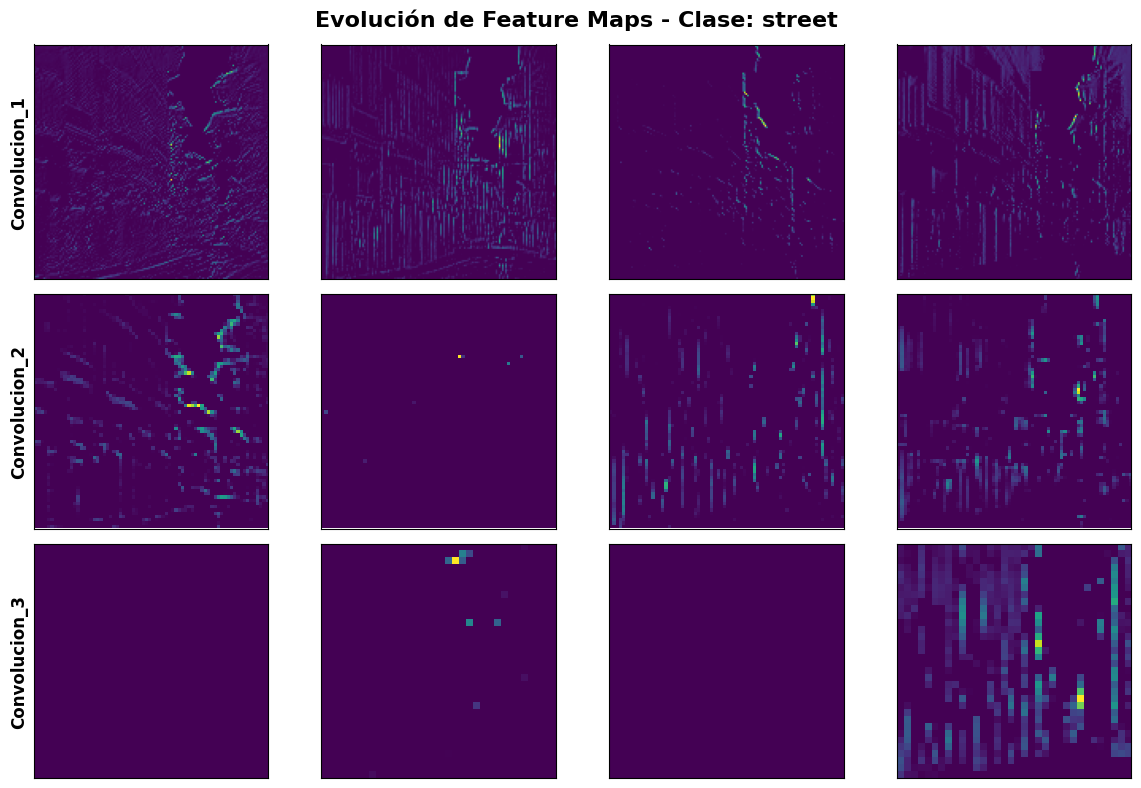

In [ ]:
# 1. Extraer una sola imagen de prueba
for images, labels in test_ds.unbatch().take(1):
    imagen_prueba = images.numpy()
    etiqueta_real = class_names[np.argmax(labels.numpy())]
    break

# 2. Definir las capas convolucionales objetivo
capas_objetivo = ['Convolucion_1', 'Convolucion_2', 'Convolucion_3']
feature_maps = {}

# 3. Propagación manual capa por capa
x = tf.expand_dims(imagen_prueba, axis=0)
for capa in modelo_cnn.layers:
    x = capa(x)
    if capa.name in capas_objetivo:
        feature_maps[capa.name] = x.numpy()[0]

# 4. Visualizar la evolución jerárquica (4 filtros por capa)
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
fig.suptitle(f"Evolución de Feature Maps - Clase: {etiqueta_real}", fontsize=16, fontweight='bold')

for i, nombre_capa in enumerate(capas_objetivo):
    mapas = feature_maps[nombre_capa]
    for j in range(4): # Mostrar los primeros 4 filtros de cada capa
        ax = axes[i, j]
        ax.imshow(mapas[:, :, j], cmap='viridis')
        if j == 0:
            ax.set_ylabel(nombre_capa, fontsize=12, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

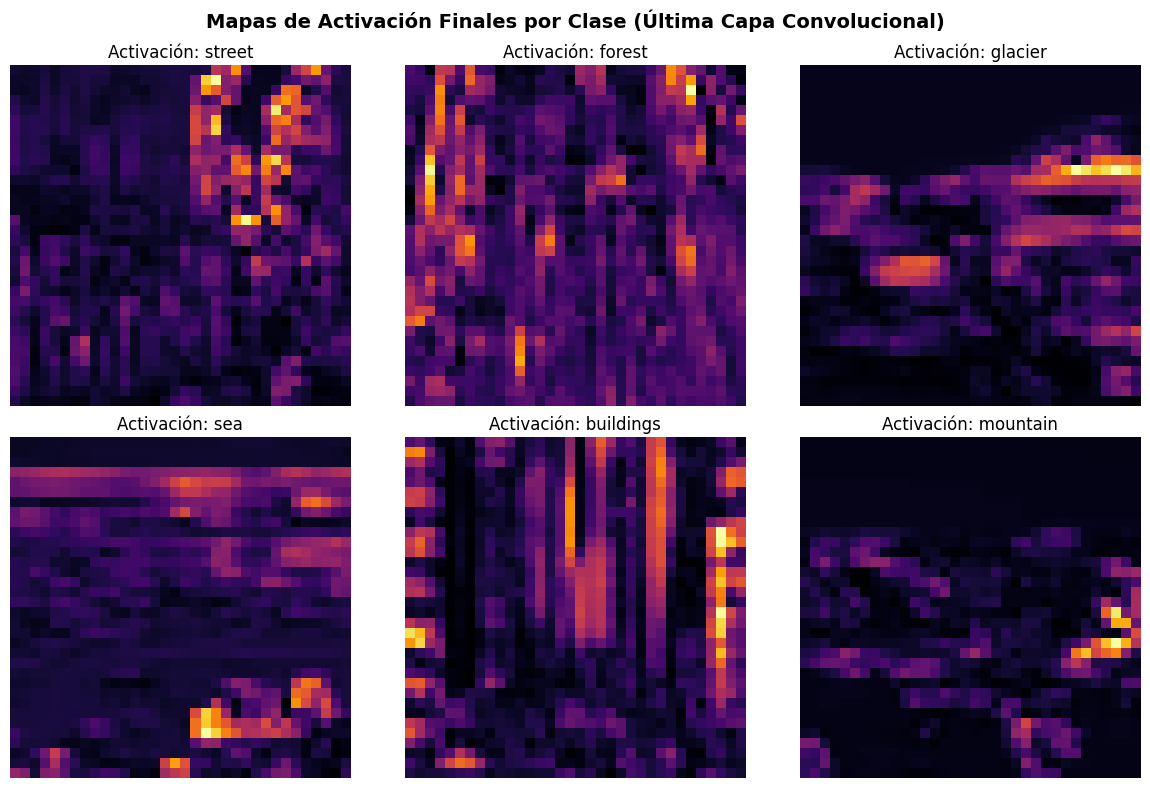

In [ ]:
# Visualizar el mapa de activación final (Convolucion_3) para una imagen de CADA CLASE
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

clases_encontradas = []

# Iteramos sobre el dataset de validación hasta encontrar 1 ejemplo de cada clase
for images, labels in test_ds.unbatch().take(500):
    clase_idx = np.argmax(labels.numpy())
    clase_nombre = class_names[clase_idx]

    if clase_nombre not in clases_encontradas:
        clases_encontradas.append(clase_nombre)

        # Pasamos esta imagen por la red hasta la última convolución
        x = tf.expand_dims(images, axis=0)
        for layer in modelo_cnn.layers:
            x = layer(x)
            if layer.name == 'Convolucion_3':
                mapa_activacion = x.numpy()[0]
                break

        # Promediamos todos los filtros de esa capa para tener un único "Mapa de Activación" general
        mapa_promedio = np.mean(mapa_activacion, axis=-1)

        idx_plot = len(clases_encontradas) - 1
        axes[idx_plot].imshow(mapa_promedio, cmap='inferno')
        axes[idx_plot].set_title(f"Activación: {clase_nombre}")
        axes[idx_plot].axis('off')

    if len(clases_encontradas) == NUM_CLASSES:
        break

plt.suptitle("Mapas de Activación Finales por Clase (Última Capa Convolucional)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
